# Recovering the thermodynamic GCF from finite-size eigenvalues

## 1. Scope and finite-size target

This notebook compares ways of extracting the thermodynamic generating cumulant
function (GCF) from precomputed finite-size eigenvalues. The tilted Liouvillian,
vectorized dynamics, observables, and simulation workflow are documented in
[`README.md`](README.md) and are not repeated here.

For a diffusive chain,

$$
\operatorname{Re}\lambda_N(u)
= a_0(u)+\frac{F(u)}{N}+\frac{a_2(u)}{N^2}+\cdots .
$$

Writing $x=1/N$, the desired thermodynamic GCF is

$$
F(u)=\left.\frac{d\operatorname{Re}\lambda_N(u)}{dx}\right|_{x=0},
\qquad a_0(u)\stackrel{\mathrm{diffusive}}{=}0.
$$

The inverse-size eigenvalues are used internally for fitting. **The extrapolation figures plot GCF versus counting field $u$:** faint curves show the
finite-size estimates $F_N=N\operatorname{Re}\lambda_N$, colored curves show the
thermodynamic extrapolations, and the black dashed curve is the supplied ISEP
prediction.
The final section separately demonstrates a six-site TEBD simulation and its
time-dependent observables. It does not supply the finite-size eigenvalues above.


## 2. Setup

Run from top to bottom in `GCF_package_Github`. Change `CHI`, `U`, or `N_MAX` to
inspect a different worked point. `N_MAX` also sets which system sizes enter all
extrapolations. Figures are saved only as PDF files.

In [1]:
using Pkg
Pkg.activate(pwd(); io=devnull)

using CSV, DataFrames, LinearAlgebra, Plots, HDF5
gr()

ROOT = pwd()
DATA_FILE = joinpath(ROOT, "eigenvalues.csv")
THEORY_FILE = joinpath(ROOT, "ISEP_theory.csv")
PLOT_DIR = ROOT  # save PDFs alongside this notebook

# Parameters used for the highlighted numerical row in each method.
CHIS = [100, 120]           # both bond dimensions are plotted
CHI = 120                  # highlighted row in the numerical comparison
U = -0.5
N_MAX = 200                 # use 100 or 200 for the bundled data

default(
    fontfamily="Computer Modern",
    guidefontsize=11,
    tickfontsize=9,
    legendfontsize=7,
    linewidth=2,
    framestyle=:box,
    gridalpha=0.20,
    dpi=100,
    left_margin=14Plots.mm,
    bottom_margin=10Plots.mm,
    top_margin=6Plots.mm,
)

## 3. Load the eigenvalues

The input columns are `chi`, `N`, `u`, and `lambda_real`. Missing sizes remain
missing. For each method, the code independently fits every available `(chi,u)`
group using sizes `N <= N_MAX`.

The plotting helper below only handles presentation; the fitting formula for each
method remains visible in that method's own cell.

In [2]:
data = filter(row -> row.chi in CHIS, CSV.read(DATA_FILE, DataFrame))
theory = CSV.read(THEORY_FILE, DataFrame)

@assert nrow(unique(data, [:chi, :N, :u])) == nrow(data) "Duplicate rows"
@assert all(data.N .> 0) "System sizes must be positive"
@assert all(isfinite, data.lambda_real) "Eigenvalues must be finite"

data.F_N = data.N .* data.lambda_real       # finite-size GCF estimate
fit_data = filter(row -> row.N <= N_MAX, data)
@assert !isempty(fit_data) "No data satisfy N <= N_MAX"

# Input: a method label and a function accepting one (chi,u) group of rows.
# Output: a DataFrame containing chi, u, M, degree, a0 and GCF slope F.
# Fits use the global fit_data table, restricted by N_MAX and CHIS.
function evaluate_method(method_name, estimator)
    rows = NamedTuple[]
    for group in groupby(fit_data, [:chi, :u])
        nrow(group) >= 2 || continue
        estimate = estimator(group)
        push!(rows, merge((method=method_name,
                           chi=first(group.chi),
                           u=first(group.u),
                           M=nrow(group)), estimate))
    end
    table = DataFrame(rows)
    sort!(table, [:chi, :u])
    return table
end

# Input: a result DataFrame. Output: its rows at the chosen CHI and U.
worked_row(table) = filter(
    row -> row.chi == CHI && isapprox(row.u, U; atol=1e-12), table
)

# Inputs: result table, title and PDF filename. Output: a Plots figure.
# Also displays and saves that figure. Uses fit_data and theory loaded above.
# Plot GCF quantities: finite-size F_N, extrapolated F, and supplied ISEP F.
function plot_gcf(table, method_title, filename)
    p = plot(
        ; xlabel="counting field u",
        ylabel="GCF F(u)",
        title=method_title * "   (N <= $N_MAX)",
        legend=:outerright,
        size=(1150, 600),
    )

    # Faint blue curves show F_N=N*Re(lambda_N) at the largest available chi.
    largest_chi = maximum(data.chi)
    sizes = sort(unique(fit_data.N))
    size_colors = palette(:Blues, length(sizes) + 2)[3:end]
    for (N, color) in zip(sizes, size_colors)
        finite = filter(row -> row.N == N && row.chi == largest_chi, fit_data)
        sort!(finite, :u)
        plot!(p, finite.u, finite.F_N; color=color, alpha=0.55,
              marker=:circle, markersize=2.8, linewidth=1.0,
              label="finite N=$N, chi=$largest_chi")
    end

    # ISEP is plotted only as an external benchmark; it never enters a fit.
    umin, umax = extrema(fit_data.u)
    theory_visible = filter(row -> umin <= row.u <= umax, theory)
    plot!(p, theory_visible.u, theory_visible.F_ISEP; color=:black,
          linestyle=:dash, linewidth=2.2, label="ISEP")

    # One extrapolated thermodynamic GCF curve for each bond dimension.
    chis = sort(unique(table.chi))
    colors = ["#2563A6", "#D97706", "#16877A", "#7C3AED"]
    markers = [:circle, :square, :utriangle, :diamond]
    for (index, group) in enumerate(groupby(table, :chi))
        sort!(group, :u)
        chi = first(group.chi)
        degrees = join(sort(unique(group.degree)), ",")
        plot!(p, group.u, group.F;
              color=colors[mod1(index, length(colors))],
              marker=markers[mod1(index, length(markers))],
              markersize=4, label="chi=$chi; d=$degrees")
    end

    hline!(p, [0.0]; color=:gray, linewidth=0.6, label=false)
    savefig(p, joinpath(PLOT_DIR, filename))
    display(p)
    return p
end

# ISEP value used later for the numerical accuracy table at the worked U.
theory_index = argmin(abs.(theory.u .- U))
@assert isapprox(theory.u[theory_index], U; atol=1e-12) "U is absent from theory"
F_reference = theory.F_ISEP[theory_index]

println("Loaded $(nrow(fit_data)) points with N <= $N_MAX")
println("ISEP reference F($U) = $F_reference")

Loaded 64 points with N <= 200
ISEP reference F(-0.5) = 1.4769870974111352


## 4. Method 1 — ordinary linear fit

For each fixed `(chi,u)`, fit

$$\operatorname{Re}\lambda_N=a_0+F/N$$

with both `a0` and `F` free. The fitted slope is plotted as the thermodynamic GCF
$F(u)$. This simple method cannot capture curvature in $1/N$.

Row,method,chi,u,M,degree,a0,F
,String,Int64,Float64,Int64,Int64,Float64,Float64
1,Ordinary linear,120,-0.5,4,1,0.00163417,1.18104


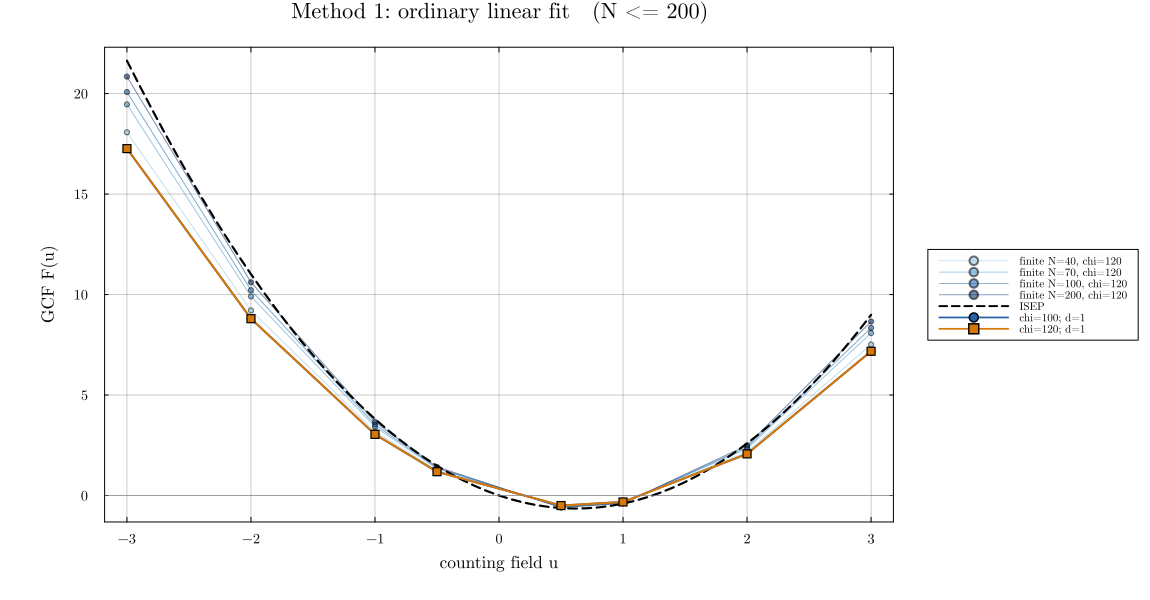

In [3]:
# Input: a DataFrame for one chi and u, with columns N and lambda_real.
# Output: (degree=1, a0, F), where F is the slope in x=1/N, the GCF.
# At least two distinct sizes are needed to determine both coefficients.
function ordinary_linear(points)
    ordered = sort(points, :N)
    x = 1.0 ./ ordered.N                    # inverse sizes
    y = copy(ordered.lambda_real)            # finite-size eigenvalues

    # The two matrix columns multiply the unknown intercept a0 and slope F.
    a0, F = hcat(ones(length(x)), x) \ y
    return (degree=1, a0=a0, F=F)
end

linear_results = evaluate_method("Ordinary linear", ordinary_linear)
display(worked_row(linear_results))
p_linear = plot_gcf(
    linear_results,
    "Method 1: ordinary linear fit",
    "method_1_GCF_ordinary_linear.pdf",
)
nothing

## 5. Method 2 — line constrained through `(0,0)`

Impose the diffusive intercept exactly:

$$
\operatorname{Re}\lambda_N=F/N,
\qquad F=\frac{\sum_i x_i y_i}{\sum_i x_i^2}.
$$

This is stable and transparent, but it still approximates every finite-size
correction by one line.

Row,method,chi,u,M,degree,a0,F
,String,Int64,Float64,Int64,Int64,Float64,Float64
1,"Constrained through (0,0)",120,-0.5,4,1,0.0,1.27402


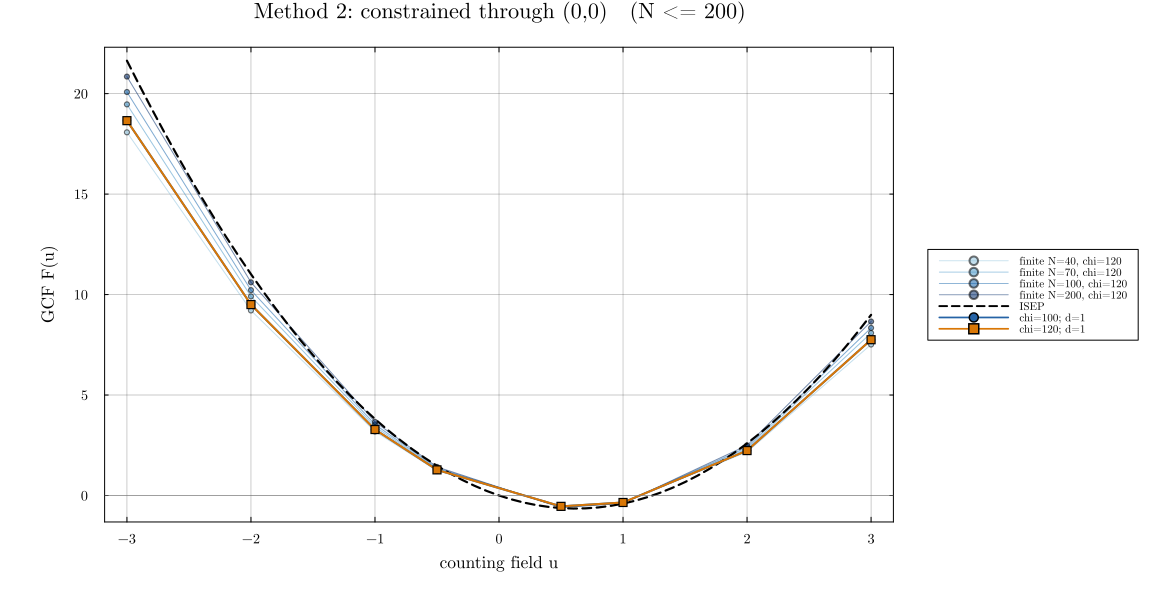

In [4]:
# Input: rows for one chi and u, containing N and lambda_real.
# Output: (degree=1, a0=0, F). F is the fitted thermodynamic GCF.
# There is one unknown slope because the intercept is fixed exactly.
function constrained_origin(points)
    ordered = sort(points, :N)
    x = 1.0 ./ ordered.N
    y = copy(ordered.lambda_real)

    # Least squares with a0 fixed exactly to zero has this one-parameter solution.
    F = dot(x, y) / dot(x, x)
    return (degree=1, a0=0.0, F=F)
end

origin_results = evaluate_method("Constrained through (0,0)", constrained_origin)
display(worked_row(origin_results))
p_origin = plot_gcf(
    origin_results,
    "Method 2: constrained through (0,0)",
    "method_2_GCF_constrained_origin.pdf",
)
nothing

## 6. Method 3 — add `(0,0)` and fit a free line

Append the expected thermodynamic point as one equally weighted observation,
then fit a free line. The intercept remains adjustable, so this differs from
Method 2. The plotted quantity is again the fitted slope $F(u)$.

Row,method,chi,u,M,degree,a0,F
,String,Int64,Float64,Int64,Int64,Float64,Float64
1,Linear + origin point,120,-0.5,4,1,0.000779134,1.22969


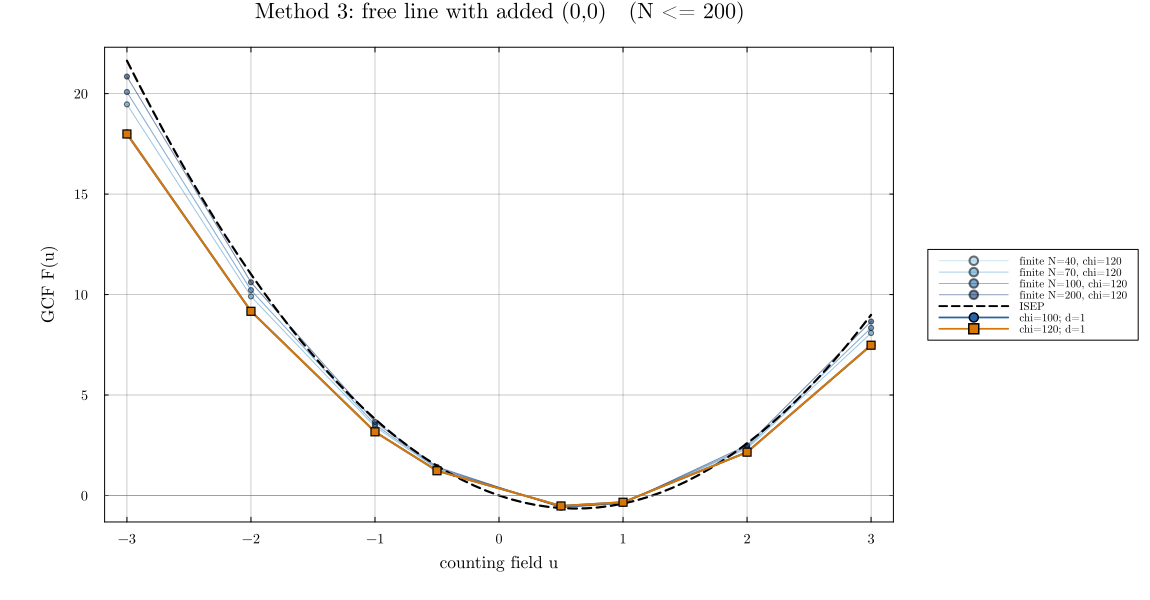

In [5]:
# Input: rows for one chi and u, containing N and lambda_real.
# Output: (degree=1, a0, F). The GCF is F, not the fitted intercept a0.
# The added point has the same weight as each measured size; a0 remains free.
function added_origin_linear(points)
    ordered = sort(points, :N)
    x = vcat(1.0 ./ ordered.N, 0.0)          # measured x plus thermodynamic x=0
    y = vcat(ordered.lambda_real, 0.0)       # measured y plus assumed y=0

    a0, F = hcat(ones(length(x)), x) \ y
    return (degree=1, a0=a0, F=F)
end

added_results = evaluate_method("Linear + origin point", added_origin_linear)
display(worked_row(added_results))
p_added = plot_gcf(
    added_results,
    "Method 3: free line with added (0,0)",
    "method_3_GCF_added_origin_linear.pdf",
)
nothing

## 7. Method 4 — selected power polynomial

For `M` measured sizes, fit degrees $d=1,\ldots,M-1$. For every candidate compute
$a_0=p(0)$ and $F=p'(0)$, then select the degree with the smallest $|a_0|$.
Rescaling measured $1/N$ values to `[-1,1]` improves numerical conditioning.
The plot shows the selected slopes $F(u)$, not the eigenvalues used in the fits.

Row,method,chi,u,M,degree,a0,F
,String,Int64,Float64,Int64,Int64,Float64,Float64
1,Selected polynomial,100,-3.0,4,3,0.000137338,21.6166
2,Selected polynomial,100,-2.0,4,3,4.6414e-5,11.0075
3,Selected polynomial,100,-1.0,4,3,1.80787e-5,3.79938
4,Selected polynomial,100,-0.5,4,3,9.86283e-6,1.47326
5,Selected polynomial,100,0.5,4,3,9.4002e-7,-0.628147
6,Selected polynomial,100,1.0,4,3,-2.64274e-6,-0.404151
7,Selected polynomial,100,2.0,4,3,2.3182e-5,2.58501
8,Selected polynomial,100,3.0,4,3,-2.19934e-5,9.003
9,Selected polynomial,120,-3.0,4,3,0.000137196,21.6167


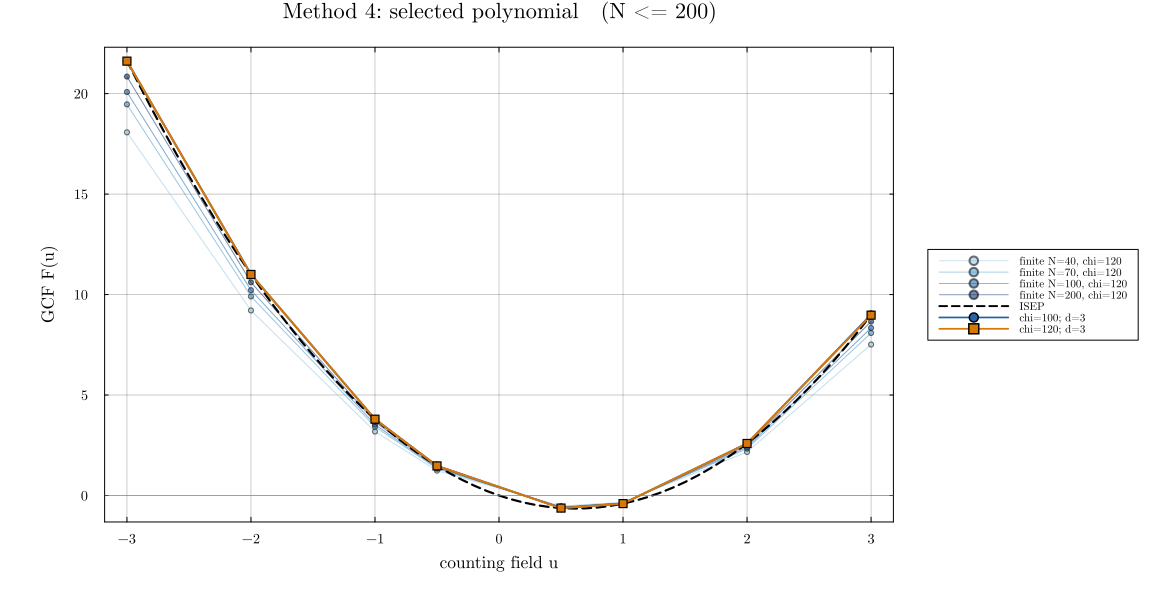

In [6]:
# scaled_power_fit inputs: inverse sizes x_data, eigenvalues y_data,
# and integer degree (at most number of distinct points minus one).
# Output: (degree, a0, F), evaluated in the ORIGINAL x=1/N coordinate.
# a0 is p(0); F is p'(0), not the first coefficient in the scaled coordinate.
# Stable polynomial fit in a scaled coordinate z. The returned F is converted
# back to the derivative with respect to the physical variable x=1/N.
function scaled_power_fit(x_data, y_data, degree)
    xmin, xmax = extrema(x_data)
    z_of(x_value) = 2 * (x_value - xmin) / (xmax - xmin) - 1
    z_data = z_of.(x_data)
    matrix = hcat([z_data .^ power for power in 0:degree]...)
    coefficients = matrix \ y_data

    z0 = z_of(0.0)
    a0 = sum(coefficients[k + 1] * z0^k for k in 0:degree)
    dz_dx = 2 / (xmax - xmin)
    F = dz_dx * sum(k * coefficients[k + 1] * z0^(k - 1)
                    for k in 1:degree)
    return (degree=degree, a0=a0, F=F)
end

# Input: rows for one chi and u, with M distinct N and lambda_real values.
# Output: (degree, a0, F) for the degree minimizing abs(a0) over 1:M-1.
# Selection does not use the ISEP curve; it only tests the intercept criterion.
function selected_polynomial(points)
    ordered = sort(points, :N)
    x = 1.0 ./ ordered.N
    y = copy(ordered.lambda_real)
    M = length(x)

    trials = [scaled_power_fit(x, y, degree) for degree in 1:(M - 1)]
    selected_index = argmin(abs.([fit.a0 for fit in trials]))
    return trials[selected_index]
end

selected_results = evaluate_method("Selected polynomial", selected_polynomial)
display(selected_results)  # reports the selected degree at EVERY chi and u
p_selected = plot_gcf(
    selected_results,
    "Method 4: selected polynomial",
    "method_4_GCF_selected_polynomial.pdf",
)
nothing

## 8. Method 5 — selected polynomial with an added `(0,0)` point

Append `(0,0)` and fit degrees $d=1,\ldots,M$ to the resulting `M+1` points.
Select the degree with the smallest $|a_0|$ and plot its slope $F(u)$. Degree `M`
can interpolate all measured points and the origin, which captures smooth
curvature well in the bundled data but may overfit noisy data.

Row,method,chi,u,M,degree,a0,F
,String,Int64,Float64,Int64,Int64,Float64,Float64
1,Selected polynomial + origin,100,-3.0,4,4,-2.76201e-17,21.6729
2,Selected polynomial + origin,100,-2.0,4,4,2.92735e-18,11.0265
3,Selected polynomial + origin,100,-1.0,4,4,2.03627e-18,3.8068
4,Selected polynomial + origin,100,-0.5,4,4,3.94717e-19,1.4773
5,Selected polynomial + origin,100,0.5,4,4,-1.57823e-18,-0.627761
6,Selected polynomial + origin,100,1.0,4,4,1.35864e-18,-0.405235
7,Selected polynomial + origin,100,2.0,4,4,2.86636e-18,2.59452
8,Selected polynomial + origin,100,3.0,4,4,1.76827e-17,8.99398
9,Selected polynomial + origin,120,-3.0,4,4,-5.52672e-17,21.6729


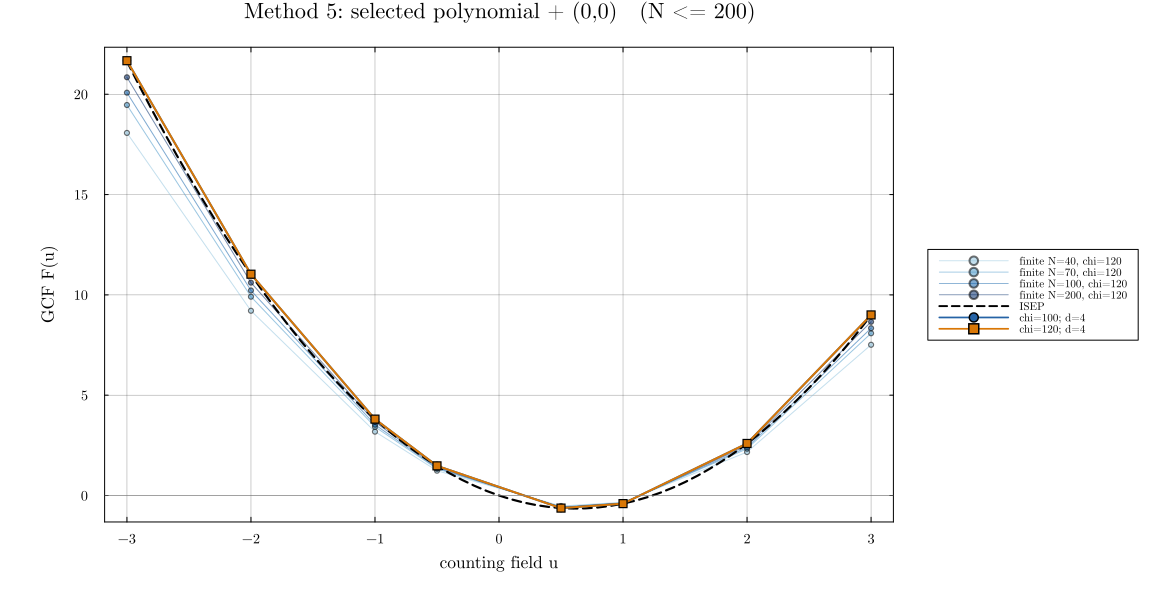

In [7]:
# Input: rows for one chi and u, with M distinct N and lambda_real values.
# Output: the selected (degree, a0, F), where F is the GCF.
# This method uses scaled_power_fit from the previous cell.
# Its extra point (0,0) is an assumed thermodynamic limit, not a measurement.
function selected_polynomial_with_origin(points)
    ordered = sort(points, :N)
    measured_x = 1.0 ./ ordered.N
    measured_y = copy(ordered.lambda_real)
    M = length(measured_x)

    # Add the expected thermodynamic point before testing degrees 1,...,M.
    x = vcat(measured_x, 0.0)
    y = vcat(measured_y, 0.0)
    trials = [scaled_power_fit(x, y, degree) for degree in 1:M]
    selected_index = argmin(abs.([fit.a0 for fit in trials]))
    return trials[selected_index]
end

selected_origin_results = evaluate_method(
    "Selected polynomial + origin",
    selected_polynomial_with_origin,
)
display(selected_origin_results)  # selected degree at EVERY chi and u
p_selected_origin = plot_gcf(
    selected_origin_results,
    "Method 5: selected polynomial + (0,0)",
    "method_5_GCF_selected_polynomial_with_origin.pdf",
)
nothing

## 9. Compare the recovered GCF curves

The five panels use the same GCF definition and the same `N_MAX`. The numerical
table compares the methods at the highlighted `(CHI,U)` point. The table tests accuracy against the supplied ISEP reference at this point.
A small fitted intercept alone does not guarantee an accurate slope for noisy
data, so compare the methods and bond dimensions rather than assume a winner.

Row,method,chi,u,M,degree,a0,F,abs_error_vs_ISEP
,String,Int64,Float64,Int64,Int64,Float64,Float64,Float64
1,Selected polynomial + origin,120,-0.5,4,4,-3.04932e-20,1.47705,6.44286e-5
2,Selected polynomial,120,-0.5,4,3,1.22426e-5,1.47203,0.00495505
3,"Constrained through (0,0)",120,-0.5,4,1,0.0,1.27402,0.202962
4,Linear + origin point,120,-0.5,4,1,0.000779134,1.22969,0.247294
5,Ordinary linear,120,-0.5,4,1,0.00163417,1.18104,0.295944


Most accurate here: Selected polynomial + origin
absolute error = 6.442863903388663e-5


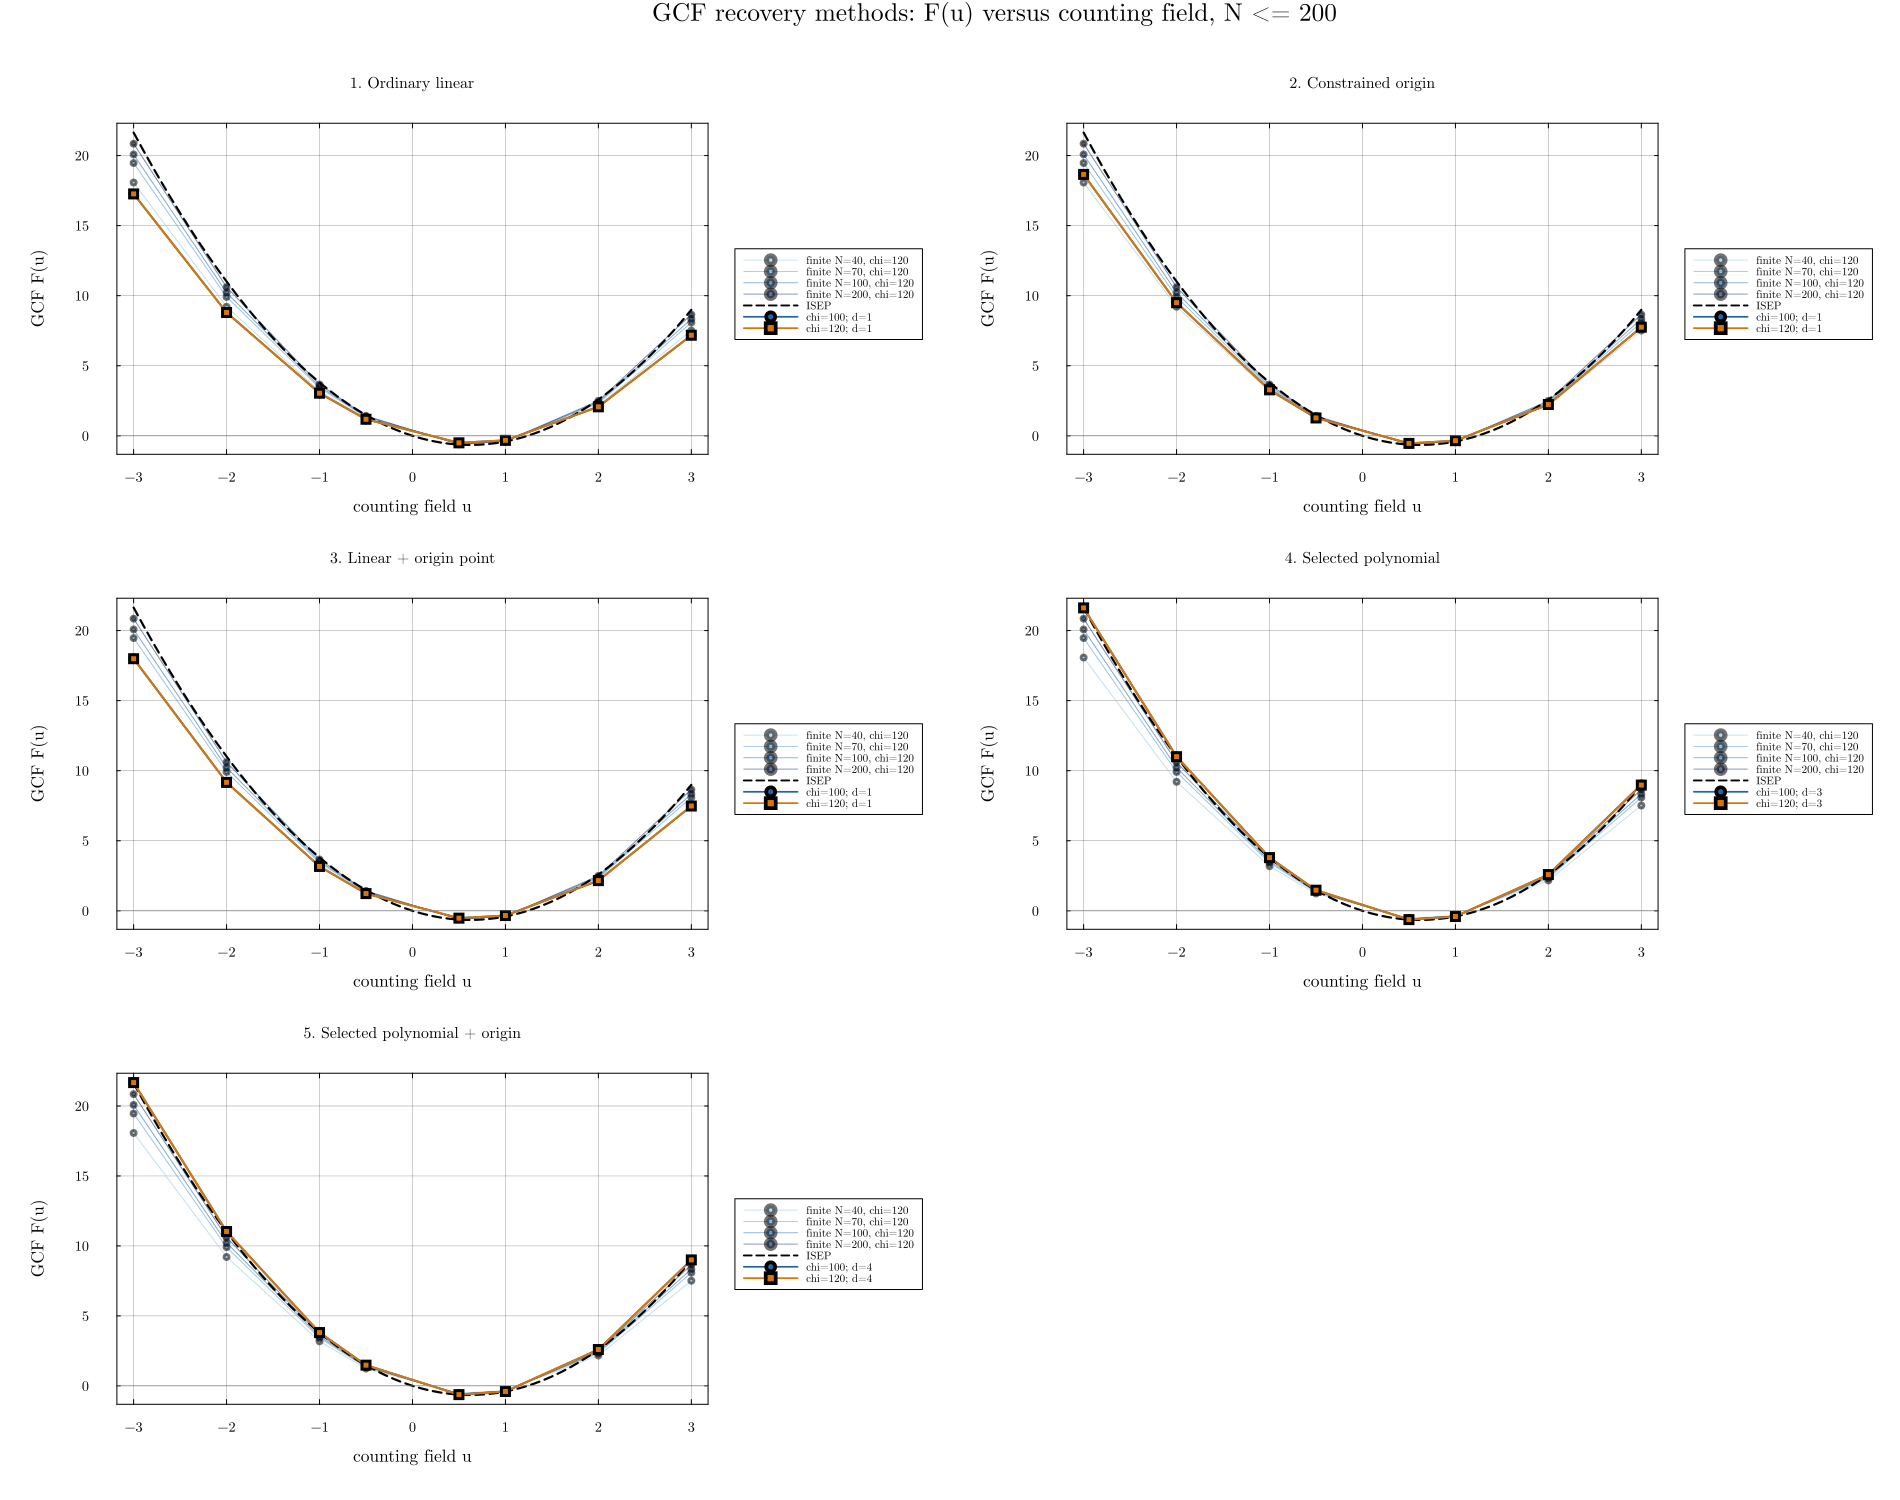

In [8]:
all_results = vcat(
    linear_results,
    origin_results,
    added_results,
    selected_results,
    selected_origin_results,
)

comparison = filter(
    row -> row.chi == CHI && isapprox(row.u, U; atol=1e-12),
    all_results,
)
comparison.abs_error_vs_ISEP = abs.(comparison.F .- F_reference)
sort!(comparison, :abs_error_vs_ISEP)
display(comparison)
println("Most accurate here: $(comparison.method[1])")
println("absolute error = $(comparison.abs_error_vs_ISEP[1])")

# Put the five GCF-versus-u figures together without introducing another fit.
# Short panel titles prevent clipping in the compact three-column layout.
combined_panels = deepcopy.([
    p_linear, p_origin, p_added, p_selected, p_selected_origin,
])
compact_titles = [
    "1. Ordinary linear",
    "2. Constrained origin",
    "3. Linear + origin point",
    "4. Selected polynomial",
    "5. Selected polynomial + origin",
]
for (index, panel) in enumerate(combined_panels)
    plot!(panel; title=compact_titles[index], titlefontsize=10,
          legend=:outerright, legendfontsize=7)
end
blank_panel = plot(; framestyle=:none, axis=false, ticks=false)
combined = plot(
    combined_panels...,
    blank_panel;
    layout=(3, 2),
    size=(1900, 1500),
    plot_title="GCF recovery methods: F(u) versus counting field, N <= $N_MAX",
    margin=5Plots.mm,
    left_margin=14Plots.mm,
    bottom_margin=10Plots.mm,
)
savefig(combined, joinpath(PLOT_DIR, "GCF_all_methods_comparison.pdf"))
display(combined)

## 10. Six-site example produced by `simulation_GCF.jl`

These are actual TEBD data produced by `run_example.jl`, which includes
`simulation_GCF.jl` and calls its `Time_Evolution` function. The initial state
is the infinite-temperature state $\rho(0)=I/2^6$, with trace one, at $t=0$.
Run `julia --project=. run_example.jl initial_N6.h5 .` to reproduce the saved
`data.h5` and `rho.h5` (this overwrites these two example outputs).

The example uses $N=6$, $\epsilon=-1$, $\eta=0.2$, $\Delta=0.5$, $\mu=0.3$,
$\gamma=1$, $u=-0.5$, and TEBD2 with $\delta t=0.01$ for 100 steps ($t=1$).
The bond-dimension cap is 16 for steps 1–50 and 32 for steps 51–100;
the truncation cutoff is $10^{-10}$. Measurements are saved every five steps,
including $t=0$ and the final time. These are short-time dynamics, not evidence
of convergence to the dominant tilted eigenmode.

The three plots below show:

- `Log_trace`: $\log|\mathrm{Tr}\,\rho_u(t)|$, including the accumulated
  normalization removed during evolution. At nonzero tilt the trace need not
  remain one.
- Pauli magnetization current on bond $(3,4)$, directed from site 3 to site 4.
- Connected correlation $C^{zz}_{3,4}=\langle\sigma^z_3\sigma^z_4\rangle
  -\langle\sigma^z_3\rangle\langle\sigma^z_4\rangle$.

Current and correlations are normalized by the tilted state's trace.
`SITE=3` below is editable; it selects the left site of the measured bond.


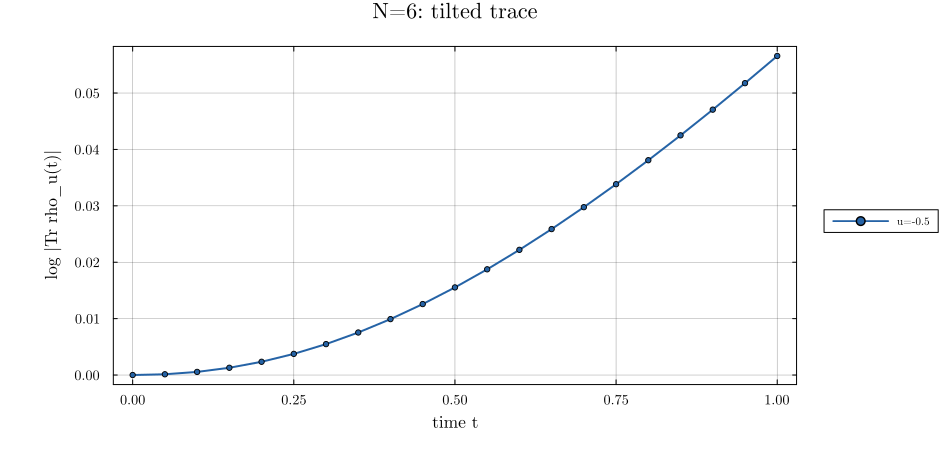

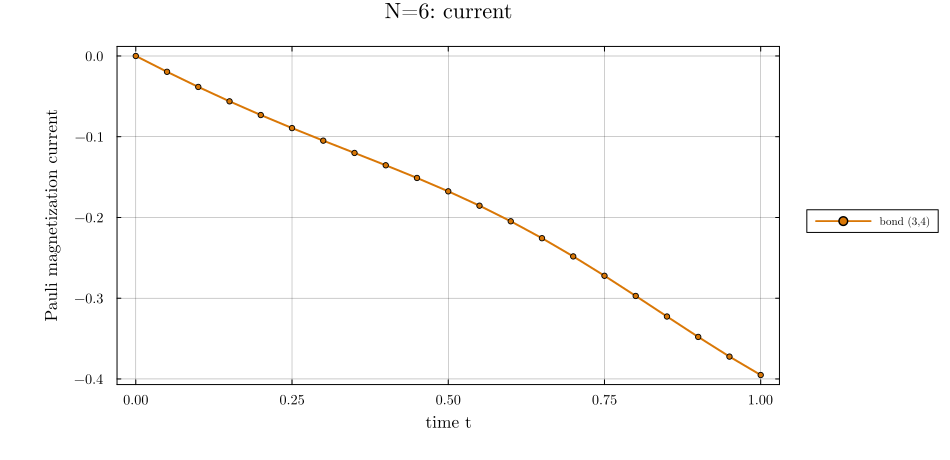

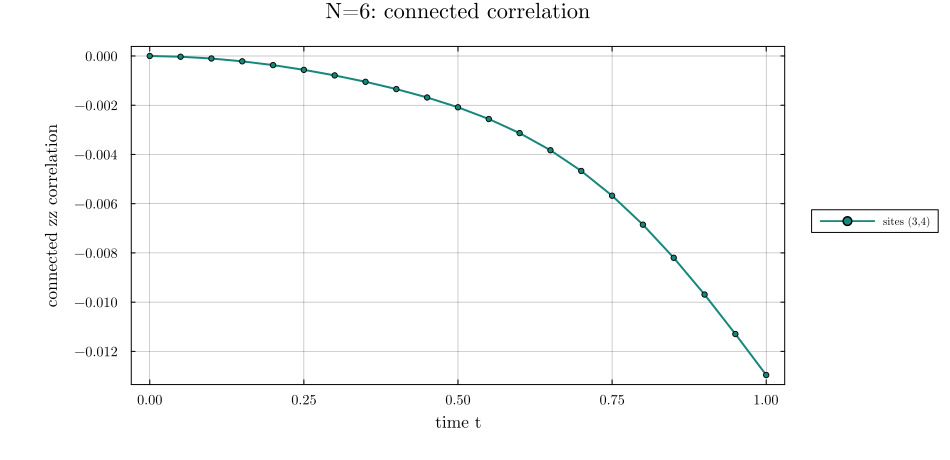

In [9]:
# Input: the HDF5 measurement file produced by Time_Evolution.
# Output: three PDF figures displayed here; no fitting is involved.
# HDF5.read keeps the Julia array convention: time is the first dimension.
simulation = h5open(read, joinpath(ROOT, "data.h5"), "r")
t = simulation["t"]
settings = simulation["parameters"]
SITE = 3                              # current bond and zz pair: (SITE, SITE+1)
@assert settings["L"] == 6
@assert 1 <= SITE < settings["L"]
@assert length(t) == 21 && isapprox(first(t), 0.0) && isapprox(last(t), 1.0)

logtrace = simulation["Log_trace"]
current = simulation["current"][:, SITE]
zz = simulation["zz_correlation"][:, SITE, SITE+1]
# Infinite temperature provides a simple check on the first saved measurement.
@assert abs(first(logtrace)) < 1e-10
@assert abs(first(current)) < 1e-10 && abs(first(zz)) < 1e-10
@assert all(isfinite, logtrace) && all(isfinite, current) && all(isfinite, zz)

p_logtrace = plot(t, logtrace; xlabel="time t", ylabel="log |Tr rho_u(t)|",
    title="N=6: tilted trace", label="u=-0.5", color="#2563A6",
    marker=:circle, markersize=3, legend=:outerright, size=(950, 460))
savefig(p_logtrace, joinpath(ROOT, "example_N6_logtrace.pdf"))
display(p_logtrace)

p_current = plot(t, current; xlabel="time t", ylabel="Pauli magnetization current",
    title="N=6: current", label="bond ($SITE,$(SITE+1))", color="#D97706",
    marker=:circle, markersize=3, legend=:outerright, size=(950, 460))
savefig(p_current, joinpath(ROOT, "example_N6_current.pdf"))
display(p_current)

p_zz = plot(t, zz; xlabel="time t", ylabel="connected zz correlation",
    title="N=6: connected correlation", label="sites ($SITE,$(SITE+1))",
    color="#16877A", marker=:circle, markersize=3,
    legend=:outerright, size=(950, 460))
savefig(p_zz, joinpath(ROOT, "example_N6_zz_correlation.pdf"))
display(p_zz)
nothing
